In [1]:
from sklearn.model_selection import train_test_split #machine learning lib with tools to prepare and eval model and divide the dataset
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.preprocessing import MultiLabelBinarizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
import pandas as pd
import numpy as np

In [2]:
df = pd.read_csv('./data/emotions_clean.csv') #import dataset and org in table - cleaned, lemmetized, stop words and negations

In [3]:
df.head() #show me first 5 rows 

,Unnamed: 0,text,emotion,doc,tokens,lemmas,clean_tokens,adjectives,clean_tokens_neg,word_count
0,0,i didnt feel humiliated,sadness,i didnt feel humiliated,"['i', 'did', 'nt', 'feel', 'humiliated']","['I', 'do', 'not', 'feel', 'humiliated']","['feel', 'humiliated']",['humiliated'],"['not_feel', 'humiliated']",5
1,1,i can go from feeling so hopeless to so damned...,sadness,i can go from feeling so hopeless to so damned...,"['i', 'can', 'go', 'from', 'feeling', 'so', 'h...","['I', 'can', 'go', 'from', 'feel', 'so', 'hope...","['feel', 'hopeless', 'damned', 'hopeful', 'car...","['hopeless', 'hopeful', 'awake']","['feel', 'hopeless', 'damned', 'hopeful', 'car...",21
2,2,im grabbing a minute to post i feel greedy wrong,anger,im grabbing a minute to post i feel greedy wrong,"['i', 'm', 'grabbing', 'a', 'minute', 'to', 'p...","['I', 'm', 'grab', 'a', 'minute', 'to', 'post'...","['m', 'grab', 'minute', 'post', 'feel', 'greed...","['greedy', 'wrong']","['m', 'grab', 'minute', 'post', 'feel', 'greed...",11
3,3,i am ever feeling nostalgic about the fireplac...,love,i am ever feeling nostalgic about the fireplac...,"['i', 'am', 'ever', 'feeling', 'nostalgic', 'a...","['I', 'be', 'ever', 'feel', 'nostalgic', 'abou...","['feel', 'nostalgic', 'fireplace', 'know', 'pr...",['nostalgic'],"['feel', 'nostalgic', 'fireplace', 'know', 'pr...",18
4,4,i am feeling grouchy,anger,i am feeling grouchy,"['i', 'am', 'feeling', 'grouchy']","['I', 'be', 'feel', 'grouchy']","['feel', 'grouchy']",['grouchy'],"['feel', 'grouchy']",4


In [4]:
df["emotion"].value_counts() #selects emotions column and counts unique value

emotion
joy         5362
sadness     4666
anger       2159
fear        1937
love        1304
surprise     572
Name: count, dtype: int64

In [5]:
df.shape

(16000, 10)

In [6]:
df.tail(10) #shows last 10 rows 

,Unnamed: 0,text,emotion,doc,tokens,lemmas,clean_tokens,adjectives,clean_tokens_neg,word_count
15990,15990,i feel really glad that i dont look like the c...,joy,i feel really glad that i dont look like the c...,"['i', 'feel', 'really', 'glad', 'that', 'i', '...","['I', 'feel', 'really', 'glad', 'that', 'I', '...","['feel', 'glad', 'look', 'like', 'celebrity', ...","['glad', 'beautiful']","['feel', 'glad', 'not_look', 'like', 'celebrit...",21
15991,15991,i have wanted to perhaps convey my feelings of...,sadness,i have wanted to perhaps convey my feelings of...,"['i', 'have', 'wanted', 'to', 'perhaps', 'conv...","['I', 'have', 'want', 'to', 'perhaps', 'convey...","['want', 'convey', 'feeling', 'matter', 'inste...",['irrelevant'],"['want', 'convey', 'feeling', 'matter', 'inste...",28
15992,15992,i moved away he said something that made me fe...,anger,i moved away he said something that made me fe...,"['i', 'moved', 'away', 'he', 'said', 'somethin...","['I', 'move', 'away', 'he', 'say', 'something'...","['away', 'feel', 'violent']",['violent'],"['move', 'away', 'say', 'feel', 'violent', 'no...",20
15993,15993,i most days feel like if braeden and calvin ar...,joy,i most days feel like if braeden and calvin ar...,"['i', 'most', 'days', 'feel', 'like', 'if', 'b...","['I', 'most', 'day', 'feel', 'like', 'if', 'br...","['day', 'feel', 'like', 'braeden', 'calvin', '...","['most', 'happy', 'successful']","['day', 'feel', 'like', 'braeden', 'calvin', '...",18
15994,15994,i feel so sympathetic empathetic towards them,love,i feel so sympathetic empathetic towards them,"['i', 'feel', 'so', 'sympathetic', 'empathetic...","['I', 'feel', 'so', 'sympathetic', 'empathetic...","['feel', 'sympathetic', 'empathetic']",['sympathetic'],"['feel', 'sympathetic', 'empathetic']",7
15995,15995,i just had a very brief time in the beanbag an...,sadness,i just had a very brief time in the beanbag an...,"['i', 'just', 'had', 'a', 'very', 'brief', 'ti...","['I', 'just', 'have', 'a', 'very', 'brief', 't...","['brief', 'time', 'beanbag', 'anna', 'feel', '...",['brief'],"['brief', 'time', 'beanbag', 'say', 'anna', 'f...",24
15996,15996,i am now turning and i feel pathetic that i am...,sadness,i am now turning and i feel pathetic that i am...,"['i', 'am', 'now', 'turning', 'and', 'i', 'fee...","['I', 'be', 'now', 'turn', 'and', 'I', 'feel',...","['turn', 'feel', 'pathetic', 'wait', 'table', ...",['pathetic'],"['turn', 'feel', 'pathetic', 'wait', 'table', ...",20
15997,15997,i feel strong and good overall,joy,i feel strong and good overall,"['i', 'feel', 'strong', 'and', 'good', 'overall']","['I', 'feel', 'strong', 'and', 'good', 'overall']","['feel', 'strong', 'good', 'overall']","['strong', 'good']","['feel', 'strong', 'good', 'overall']",6
15998,15998,i feel like this was such a rude comment and i...,anger,i feel like this was such a rude comment and i...,"['i', 'feel', 'like', 'this', 'was', 'such', '...","['I', 'feel', 'like', 'this', 'be', 'such', 'a...","['feel', 'like', 'rude', 'comment', 'm', 'glad...","['rude', 'glad']","['feel', 'like', 'rude', 'comment', 'm', 'glad...",15
15999,15999,i know a lot but i feel so stupid because i ca...,sadness,i know a lot but i feel so stupid because i ca...,"['i', 'know', 'a', 'lot', 'but', 'i', 'feel', ...","['I', 'know', 'a', 'lot', 'but', 'I', 'feel', ...","['know', 'lot', 'feel', 'stupid', 'portray']",['stupid'],"['know', 'lot', 'feel', 'stupid', 'not_portray']",15


In [7]:

print("Dataset shape:", df.shape) #how many rows and col 

print("\nColumn names:")
print(df.columns.tolist()) #names of the col

print("\nEmotion distribution:")
print(df["emotion"].value_counts()) #example belongs in each emotion -  target col


Dataset shape: (16000, 10)

Column names:
['Unnamed: 0', 'text', 'emotion', 'doc', 'tokens', 'lemmas', 'clean_tokens', 'adjectives', 'clean_tokens_neg', 'word_count']

Emotion distribution:
emotion
joy         5362
sadness     4666
anger       2159
fear        1937
love        1304
surprise     572
Name: count, dtype: int64


In [8]:
X = df["text"] #model receives full sentence 
Y = df["emotion"] #model predicts emotion associated with full sentence 

In [9]:
# split the data aka unpacking 

X_train, X_test, y_train, y_test = train_test_split(
X,
Y, 
 test_size=0.20, 
 random_state=42, 
 stratify=Y #helps preserve the emotion proportions in both groups 
)




In [10]:
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import accuracy_score, classification_report

# 1. Create the model pipeline
nb_model = Pipeline([
    ("vectorizer", CountVectorizer()),
    ("classifier", MultinomialNB(alpha=1.0))
])

# 2. Train the model
nb_model.fit(X_train, y_train)

# 3. Predict emotions for unseen text
y_pred = nb_model.predict(X_test)

# 4. Evaluate the predictions
print("Accuracy:", accuracy_score(y_test, y_pred))
print("\nClassification report:")
print(classification_report(y_test, y_pred, zero_division=0))

Accuracy: 0.7484375

Classification report:
              precision    recall  f1-score   support

       anger       0.89      0.57      0.69       432
        fear       0.87      0.53      0.66       387
         joy       0.71      0.94      0.81      1072
        love       0.88      0.23      0.36       261
     sadness       0.73      0.93      0.82       933
    surprise       1.00      0.03      0.07       115

    accuracy                           0.75      3200
   macro avg       0.85      0.54      0.57      3200
weighted avg       0.78      0.75      0.72      3200



In [11]:
results = pd.DataFrame({
    "text": X_test,
    "actual": y_test,
    "predicted": y_pred
})

mistakes = results[results["actual"] != results["predicted"]]

mistakes.head(5)

,text,actual,predicted
3348,i have a feeling of being scared but also know...,fear,sadness
833,i have admitted defeat and asked the other hal...,fear,sadness
8640,i feel like we tortured him that whole time,fear,anger
11658,i know that when i am feeling distraught or mo...,fear,joy
5791,i feel much gratitude and thanks for finally a...,love,joy


In [12]:
from sklearn.metrics import classification_report

print(classification_report(
    y_test,
    y_pred,
    zero_division=0
))

              precision    recall  f1-score   support

       anger       0.89      0.57      0.69       432
        fear       0.87      0.53      0.66       387
         joy       0.71      0.94      0.81      1072
        love       0.88      0.23      0.36       261
     sadness       0.73      0.93      0.82       933
    surprise       1.00      0.03      0.07       115

    accuracy                           0.75      3200
   macro avg       0.85      0.54      0.57      3200
weighted avg       0.78      0.75      0.72      3200



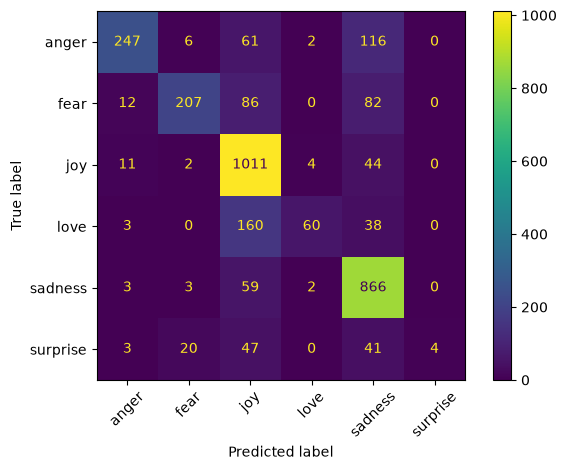

In [13]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

labels = sorted(y_test.unique())

cm = confusion_matrix(
    y_test,
    y_pred,
    labels=labels
)

display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=labels
)

display.plot(xticks_rotation=45)
plt.tight_layout()
plt.show()

In [14]:
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import classification_report

tfidf_model = Pipeline([
    ("vectorizer", TfidfVectorizer()),
    ("classifier", MultinomialNB(alpha=1.0))
])

tfidf_model.fit(X_train, y_train)

tfidf_pred = tfidf_model.predict(X_test)

print(classification_report(
    y_test,
    tfidf_pred,
    zero_division=0
))

              precision    recall  f1-score   support

       anger       0.99      0.17      0.29       432
        fear       0.95      0.14      0.24       387
         joy       0.58      0.98      0.73      1072
        love       1.00      0.02      0.04       261
     sadness       0.67      0.89      0.77       933
    surprise       0.00      0.00      0.00       115

    accuracy                           0.63      3200
   macro avg       0.70      0.37      0.35      3200
weighted avg       0.72      0.63      0.54      3200



In [15]:
from sklearn.metrics import accuracy_score, f1_score
import pandas as pd

comparison = pd.DataFrame({
    "Model": ["CountVectorizer + Naive Bayes",
              "TF-IDF + Naive Bayes"],
    "Accuracy": [
        accuracy_score(y_test, y_pred),
        accuracy_score(y_test, tfidf_pred)
    ],
    "Macro F1": [
        f1_score(y_test, y_pred, average="macro"),
        f1_score(y_test, tfidf_pred, average="macro")
    ],
    "Weighted F1": [
        f1_score(y_test, y_pred, average="weighted"),
        f1_score(y_test, tfidf_pred, average="weighted")
    ]
})

comparison

,Model,Accuracy,Macro F1,Weighted F1
0,CountVectorizer + Naive Bayes,0.748437,0.569374,0.715655
1,TF-IDF + Naive Bayes,0.630313,0.345361,0.539080


In [16]:
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import classification_report

for alpha in [0.1, 0.5, 1.0, 2.0]:
    model = Pipeline([
        ("vectorizer", CountVectorizer()),
        ("classifier", MultinomialNB(alpha=alpha))
    ])

    model.fit(X_train, y_train)
    predictions = model.predict(X_test)

    macro_f1 = f1_score(
        y_test, predictions, average="macro"
    )

    print(f"\nAlpha = {alpha} | Macro F1 = {macro_f1:.3f}")


Alpha = 0.1 | Macro F1 = 0.701

Alpha = 0.5 | Macro F1 = 0.666

Alpha = 1.0 | Macro F1 = 0.569

Alpha = 2.0 | Macro F1 = 0.424


              precision    recall  f1-score   support

       anger       0.74      0.72      0.73       432
        fear       0.71      0.71      0.71       387
         joy       0.81      0.85      0.83      1072
        love       0.69      0.56      0.62       261
     sadness       0.81      0.84      0.83       933
    surprise       0.61      0.42      0.49       115

    accuracy                           0.78      3200
   macro avg       0.73      0.68      0.70      3200
weighted avg       0.77      0.78      0.77      3200



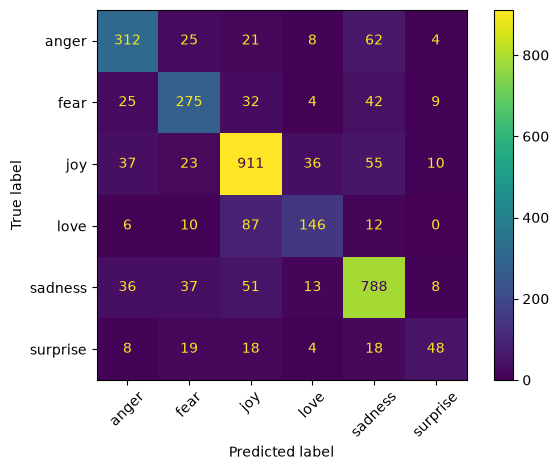

In [17]:

from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import classification_report, confusion_matrix
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

# Build the model using the best alpha so far
best_model = Pipeline([
    ("vectorizer", CountVectorizer()),
    ("classifier", MultinomialNB(alpha=0.1))
])

# Train using the training data only
best_model.fit(X_train, y_train)

# Predict the emotions for unseen test examples
best_pred = best_model.predict(X_test)

# Evaluate every emotion
print(classification_report(
    y_test,
    best_pred,
    zero_division=0
))

# Visualize the errors
ConfusionMatrixDisplay.from_predictions(
    y_test,
    best_pred,
    xticks_rotation=45
)

plt.tight_layout()
plt.show()


In [18]:

from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.naive_bayes import MultinomialNB
import pandas as pd

alphas = [0.01, 0.03, 0.05, 0.1, 0.2, 0.3, 0.5]

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

results = []

for alpha in alphas:
    model = Pipeline([
        ("vectorizer", CountVectorizer()),
        ("classifier", MultinomialNB(alpha=alpha))
    ])

    scores = cross_val_score(
        model,
        X_train,
        y_train,
        cv=cv,
        scoring="f1_macro"
    )

    results.append({
        "alpha": alpha,
        "mean_macro_f1": scores.mean(),
        "std_macro_f1": scores.std()
    })

results_df = pd.DataFrame(results)
results_df.sort_values(
    "mean_macro_f1",
    ascending=False
)


,alpha,mean_macro_f1,std_macro_f1
4,0.20,0.691919,0.009262
3,0.10,0.683985,0.007206
5,0.30,0.678923,0.006770
2,0.05,0.666985,0.005186
1,0.03,0.655747,0.006675
6,0.50,0.631627,0.006611
0,0.01,0.627511,0.008458


In [19]:

from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.naive_bayes import MultinomialNB
import pandas as pd

alphas = [0.01, 0.03, 0.05, 0.1, 0.2, 0.3, 0.5]

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

results = []

for alpha in alphas:
    model = Pipeline([
        ("vectorizer", CountVectorizer()),
        ("classifier", MultinomialNB(alpha=alpha))
    ])

    scores = cross_val_score(
        model,
        X_train,
        y_train,
        cv=cv,
        scoring="f1_macro"
    )

    results.append({
        "alpha": alpha,
        "mean_macro_f1": scores.mean(),
        "std_macro_f1": scores.std()
    })

results_df = pd.DataFrame(results)

results_df.sort_values(
    "mean_macro_f1",
    ascending=False
)


,alpha,mean_macro_f1,std_macro_f1
4,0.20,0.691919,0.009262
3,0.10,0.683985,0.007206
5,0.30,0.678923,0.006770
2,0.05,0.666985,0.005186
1,0.03,0.655747,0.006675
6,0.50,0.631627,0.006611
0,0.01,0.627511,0.008458


In [20]:
final_model = Pipeline([
    ("vectorizer", CountVectorizer()),
    ("classifier", MultinomialNB(alpha=0.2))
])

final_model.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('vectorizer', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[<U8](6,)","['anger','fear','joy','love','sadness','surprise']"
,"input input: {'filename', 'file', 'content'}, default='content'- If `'filename'`, the sequence passed as an argument to fit is expected to be a list of filenames that need reading to fetch the raw content to analyze.- If `'file'`, the sequence items must have a 'read' method (file-like object) that is called to fetch the bytes in memory.- If `'content'`, the input is expected to be a sequence of items that can be of type string or byte.",'content'
,"encoding encoding: str, default='utf-8'If bytes or files are given to analyze, this encoding is used todecode.",'utf-8'
,"decode_error decode_error: {'strict', 'ignore', 'replace'}, default='strict'Instruction on what to do if a byte sequence is given to analyze thatcontains characters not of the given `encoding`. By default, it is'strict', meaning that a UnicodeDecodeError will be raised. Othervalues are 'ignore' and 'replace'.",'strict'
,"strip_accents strip_accents: {'ascii', 'unicode'} or callable, default=NoneRemove accents and perform other character normalizationduring the preprocessing step.'ascii' is a fast method that only works on characters that havea direct ASCII mapping.'unicode' is a slightly slower method that works on any characters.None (default) means no character normalization is performed.Both 'ascii' and 'unicode' use NFKD normalization from:func:`unicodedata.normalize`.",None
,"lowercase lowercase: bool, default=TrueConvert all characters to lowercase before tokenizing.",True


In [ ]:
# Make predictions using our new model
y_pred_final = final_model.predict(X_test) #3200 test sentences 

# Check overall accuracy
print("Accuracy:", accuracy_score(y_test, y_pred_final)) #compare models guesses to actual answers 

# Check performance for each emotion
print(classification_report(y_test, y_pred_final)) # 

Accuracy: 0.7878125
              precision    recall  f1-score   support

       anger       0.76      0.73      0.75       432
        fear       0.75      0.74      0.75       387
         joy       0.82      0.86      0.84      1072
        love       0.69      0.55      0.61       261
     sadness       0.81      0.87      0.84       933
    surprise       0.70      0.35      0.47       115

    accuracy                           0.79      3200
   macro avg       0.75      0.68      0.71      3200
weighted avg       0.78      0.79      0.78      3200



In [ ]:
# Create a table of predictions
errors = pd.DataFrame({
    "text": X_test,
    "actual": y_test,
    "predicted": y_pred_final
})

# Keep only incorrect predictions
errors = errors[errors["actual"] != errors["predicted"]]

# Look at mistakes involving surprise
surprise_errors = errors[errors["actual"] == "surprise"]

print("Surprise mistakes:", len(surprise_errors))

from IPython.display import display as show_table #diaplays Jupyters table display function as a new variable
show_table(surprise_errors.head(10)) #display first 10 

Surprise mistakes: 75


,text,actual,predicted
14133,im feeling extraordinarily dazed and bewildere...,surprise,sadness
6790,i actually prefer peep toe shoes because of it...,surprise,sadness
6,ive been taking or milligrams or times recomme...,surprise,sadness
4656,i feel like im in this weird in between stage,surprise,fear
6382,i will be honest it did feel a little strange ...,surprise,fear
12154,i feel weird sharing that but this is the sour...,surprise,love
8874,i don t have the longevity or experience in th...,surprise,joy
8686,im feeling awfully overwhelmed by everything r...,surprise,anger
535,i dont know why but i had started to feel the ...,surprise,fear
9777,i don t know how sasha fierce feels i m defini...,surprise,joy


In [26]:
# Count what the model predicts instead of surprise
surprise_confusion = surprise_errors["predicted"].value_counts()

print("Surprise is being confused with:")
print(surprise_confusion)

Surprise is being confused with:
predicted
sadness    23
joy        22
fear       21
anger       5
love        4
Name: count, dtype: int64
